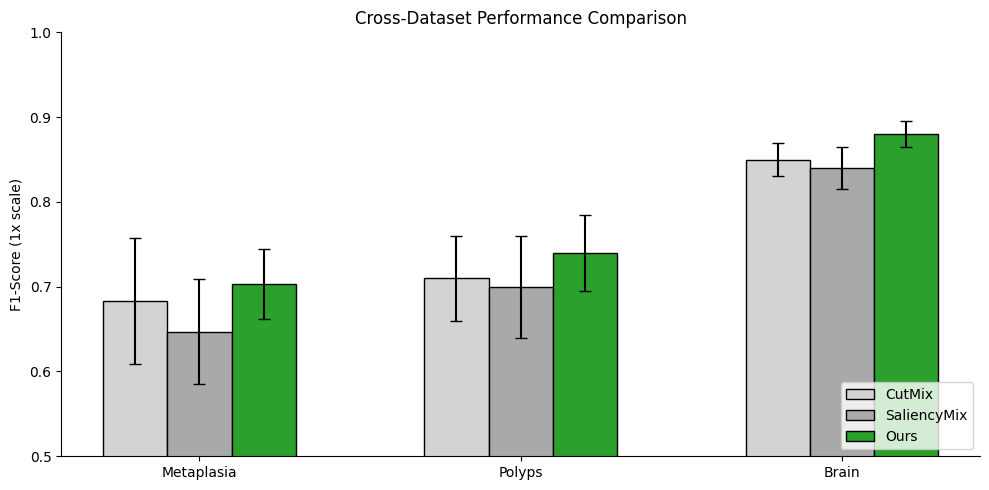

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Configuração
fig, ax = plt.subplots(figsize=(10, 5))

# Datasets e Métodos (Apenas um exemplo para 3 datasets para ilustrar)
datasets = ['Metaplasia', 'Polyps', 'Brain']
x = np.arange(len(datasets))
width = 0.2  # largura das barras

# Dados Fictícios para F1-Score a 1x (Substituir pelos seus dados)
cutmix_f1 = [0.683, 0.710, 0.850]
cutmix_std = [0.074, 0.050, 0.020]

saliency_f1 = [0.647, 0.700, 0.840]
saliency_std = [0.062, 0.060, 0.025]

ours_f1 = [0.703, 0.740, 0.880]
ours_std = [0.041, 0.045, 0.015]

# Plot de cada método agrupadamente
rects1 = ax.bar(x - width, cutmix_f1, width, yerr=cutmix_std, label='CutMix', capsize=4, color='#d3d3d3', edgecolor='black')
rects2 = ax.bar(x, saliency_f1, width, yerr=saliency_std, label='SaliencyMix', capsize=4, color='#a9a9a9', edgecolor='black')
rects3 = ax.bar(x + width, ours_f1, width, yerr=ours_std, label='Ours', capsize=4, color='#2ca02c', edgecolor='black') # Verde destaque

# Formatação
ax.set_ylabel('F1-Score (1x scale)')
ax.set_title('Cross-Dataset Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.legend(loc='lower right')
ax.set_ylim(0.5, 1.0) # Ajustar para focar nas diferenças relevantes

# Remover bordas desnecessárias para ficar com aspeto de publicação
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

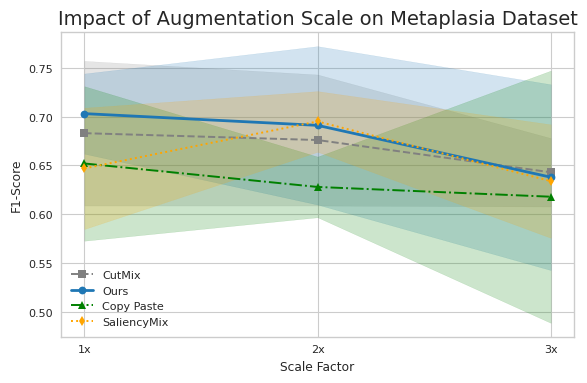

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Configuração de estilo para artigo científico
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(6, 4))

# Dados (Extraídos da sua tabela para Metaplasia - F1 Score)
factors = ['1x', '2x', '3x']
x = np.arange(len(factors))

# CutMix
cutmix_f1 = np.array([0.683, 0.676, 0.643])
cutmix_std = np.array([0.074, 0.067, 0.035])

# Ours
ours_f1 = np.array([0.703, 0.691, 0.638])
ours_std = np.array([0.041, 0.081, 0.095])

# Copy Paste
cp_f1 = np.array([0.652, 0.628, 0.618])
cp_std = np.array([0.079, 0.031, 0.129])

# SaliencyMix
salie_f1 = np.array([0.647, 0.695, 0.634])
salie_std = np.array([0.062, 0.031, 0.058])

# Plot CutMix
ax.plot(x, cutmix_f1, label='CutMix', marker='s', linestyle='--', color='gray')
ax.fill_between(x, cutmix_f1 - cutmix_std, cutmix_f1 + cutmix_std, color='gray', alpha=0.2)

# Plot Ours (Cor de destaque)
ax.plot(x, ours_f1, label='Ours', marker='o', linestyle='-', color='#1f77b4', linewidth=2)
ax.fill_between(x, ours_f1 - ours_std, ours_f1 + ours_std, color='#1f77b4', alpha=0.2)

# Plot Copy Paste
ax.plot(x, cp_f1, label='Copy Paste', marker='^', linestyle='-.', color='green')
ax.fill_between(x, cp_f1 - cp_std, cp_f1 + cp_std, color='green', alpha=0.2)

# Plot SaliencyMix
ax.plot(x, salie_f1, label='SaliencyMix', marker='d', linestyle=':', color='orange')
ax.fill_between(x, salie_f1 - salie_std, salie_f1 + salie_std, color='orange', alpha=0.2)

# Formatação
ax.set_xticks(x)
ax.set_xticklabels(factors)
ax.set_xlabel('Scale Factor')
ax.set_ylabel('F1-Score')
ax.set_title('Impact of Augmentation Scale on Metaplasia Dataset')
ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

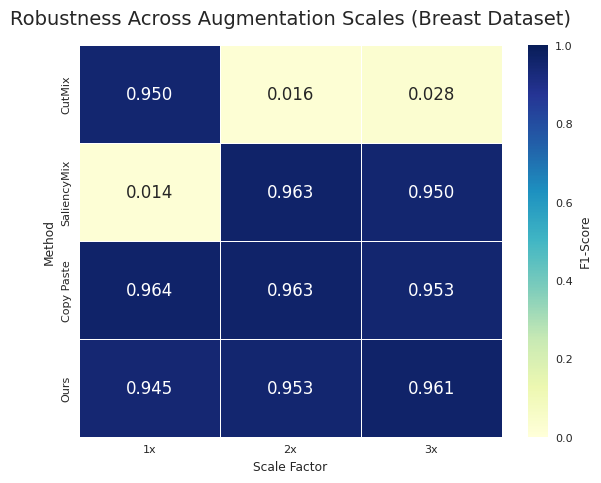

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo para artigo
plt.style.use('seaborn-v0_8-paper')
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 14})

# Dados representativos (Dataset Breast - F1 Score)
# Extraídos da sua tabela para ilustrar o contraste extremo
methods = ['CutMix', 'SaliencyMix', 'Copy Paste', 'Ours']
scales = ['1x', '2x', '3x']

# Matriz de F1-Scores (linhas=métodos, colunas=escalas)
# Valores aproximados da sua tabela "Breast" para demonstração
f1_data = np.array([
    [0.950, 0.016, 0.028], # CutMix (degrada a 2x e 3x)
    [0.014, 0.963, 0.950], # SaliencyMix (falha a 1x)
    [0.964, 0.963, 0.953], # Copy Paste
    [0.945, 0.953, 0.961]  # Ours (Estabilidade crescente)
])

# Criar a figura
fig, ax = plt.subplots(figsize=(6, 5))

# Gerar o Heatmap
# 'cmap' define a paleta: azul (frio/baixo) para vermelho (quente/alto) ou vice-versa
# vmin e vmax fixam os limites para a cor ser consistente
sns.heatmap(f1_data, annot=True, fmt=".3f", cmap="YlGnBu", 
            xticklabels=scales, yticklabels=methods, 
            vmin=0.0, vmax=1.0, linewidths=.5, ax=ax,
            cbar_kws={'label': 'F1-Score'})

ax.set_title('Robustness Across Augmentation Scales (Breast Dataset)', pad=15)
ax.set_xlabel('Scale Factor')
ax.set_ylabel('Method')

plt.tight_layout()
plt.show()

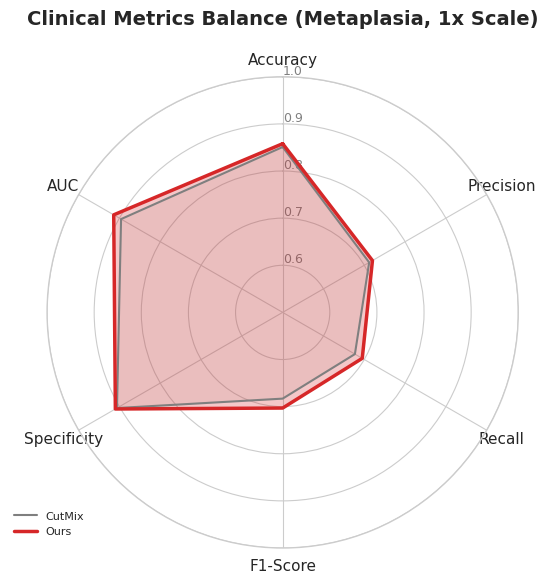

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi

# Configuração de estilo
plt.style.use('seaborn-v0_8-whitegrid')

# Métricas da tabela
categories = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Specificity', 'AUC']
N = len(categories)

# Dados (Exemplo: Dataset Metaplasia a 1x - usando os valores da sua tabela)
values_cutmix = [0.851, 0.712, 0.677, 0.683, 0.906, 0.896]
values_ours = [0.858, 0.720, 0.695, 0.703, 0.910, 0.914]

# Precisamos repetir o primeiro valor no final para fechar o polígono do gráfico
values_cutmix += values_cutmix[:1]
values_ours += values_ours[:1]

# Calcular os ângulos para cada eixo no radar
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

# Inicializar o layout polar
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Fixar a orientação (primeira métrica no topo) e desenhar os eixos
ax.set_theta_offset(pi / 2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], categories, size=11)

# Desenhar os rótulos do eixo Y (limites ajustados ao intervalo real dos seus dados)
ax.set_rlabel_position(0)
plt.yticks([0.6, 0.7, 0.8, 0.9, 1.0], ["0.6", "0.7", "0.8", "0.9", "1.0"], color="grey", size=9)
plt.ylim(0.5, 1.0) # O limite mínimo é 0.5 para ampliar a diferença visual na zona de 0.6-0.9

# Plot do CutMix (Baseline)
ax.plot(angles, values_cutmix, linewidth=1.5, linestyle='solid', label='CutMix', color='#7f7f7f')
ax.fill(angles, values_cutmix, color='#7f7f7f', alpha=0.1)

# Plot do seu método (Ours) - Destacado
ax.plot(angles, values_ours, linewidth=2.5, linestyle='solid', label='Ours', color='#d62728') # Vermelho destaque
ax.fill(angles, values_ours, color='#d62728', alpha=0.25)

# Adicionar legenda e título
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.title('Clinical Metrics Balance (Metaplasia, 1x Scale)', size=14, pad=20, weight='bold')

plt.tight_layout()
plt.show()

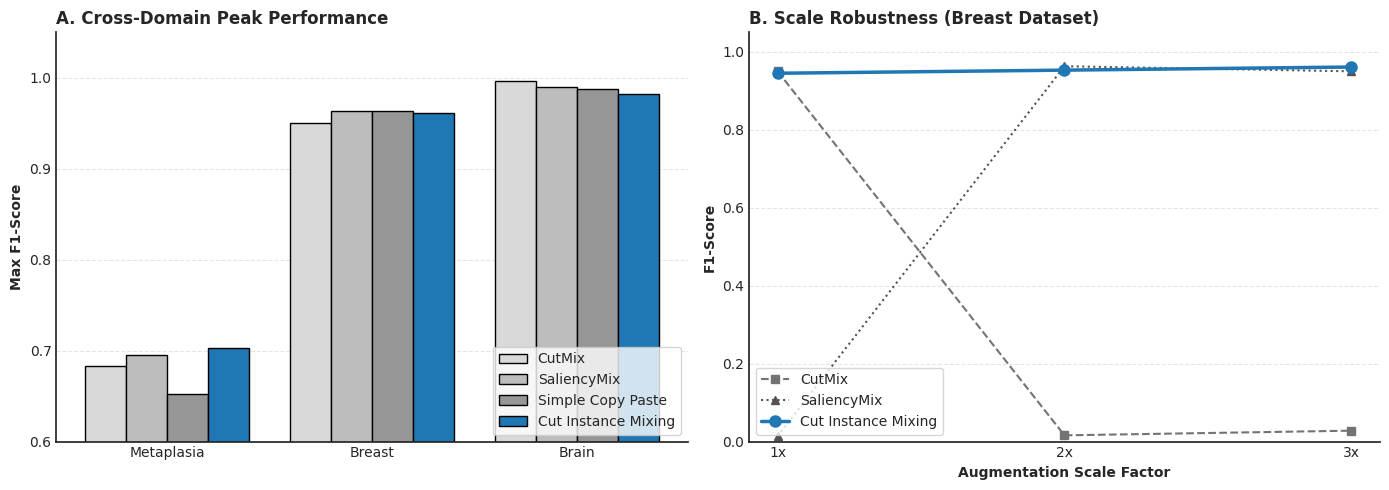

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Configuração global para estilo científico
plt.style.use('seaborn-v0_8-white')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ==========================================
# PAINEL A: Gráfico de Barras Cross-Domain
# ==========================================
datasets = ['Metaplasia', 'Breast', 'Brain']
x = np.arange(len(datasets))
width = 0.2

# Dados do melhor F1-Score alcançado (extraídos da tabela resumo)
f1_cutmix = [0.683, 0.950, 0.996]
f1_salmix = [0.695, 0.963, 0.990]
f1_copypaste = [0.652, 0.964, 0.988]
f1_ours = [0.703, 0.961, 0.982] # Cut Instance Mixing

# Desenhar barras
ax1.bar(x - 1.5*width, f1_cutmix, width, label='CutMix', color='#d9d9d9', edgecolor='black')
ax1.bar(x - 0.5*width, f1_salmix, width, label='SaliencyMix', color='#bdbdbd', edgecolor='black')
ax1.bar(x + 0.5*width, f1_copypaste, width, label='Simple Copy Paste', color='#969696', edgecolor='black')
ax1.bar(x + 1.5*width, f1_ours, width, label='Cut Instance Mixing', color='#1f77b4', edgecolor='black') # Destaque

# Formatação Painel A
ax1.set_ylabel('Max F1-Score', weight='bold')
ax1.set_title('A. Cross-Domain Peak Performance', weight='bold', loc='left')
ax1.set_xticks(x)
ax1.set_xticklabels(datasets)
ax1.set_ylim(0.6, 1.05)
ax1.legend(loc='lower right', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ==========================================
# PAINEL B: Estabilidade de Escala (Dataset Breast)
# ==========================================
scales = ['1x', '2x', '3x']
x_scale = np.arange(len(scales))

# Dados de evolução da tabela original do dataset Breast
evo_cutmix = [0.950, 0.016, 0.028]
evo_salmix = [0.014, 0.963, 0.950]
evo_ours = [0.945, 0.953, 0.961] # Demonstra crescimento/estabilidade

# Desenhar linhas de evolução
ax2.plot(x_scale, evo_cutmix, marker='s', linestyle='--', color='#737373', label='CutMix', markersize=6)
ax2.plot(x_scale, evo_salmix, marker='^', linestyle=':', color='#525252', label='SaliencyMix', markersize=6)
ax2.plot(x_scale, evo_ours, marker='o', linestyle='-', color='#1f77b4', label='Cut Instance Mixing', linewidth=2.5, markersize=8)

# Formatação Painel B
ax2.set_ylabel('F1-Score', weight='bold')
ax2.set_xlabel('Augmentation Scale Factor', weight='bold')
ax2.set_title('B. Scale Robustness (Breast Dataset)', weight='bold', loc='left')
ax2.set_xticks(x_scale)
ax2.set_xticklabels(scales)
ax2.set_ylim(0.0, 1.05)
ax2.legend(loc='lower left', frameon=True)
ax2.grid(axis='y', linestyle='--', alpha=0.5)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()